# Risk Segmentation

In diesem Notebook werden die finalen Pure-Premium-Prognosen in fachlich interpretierbare Risikosegmente überführt.

Ziel ist es, Policen anhand ihres erwarteten Schadenrisikos in klar unterscheidbare Gruppen einzuteilen und diese Segmente anschließend hinsichtlich Portfolioanteil, Exposure, erwarteter Schadenkosten und relevanter Risikomerkmale zu beschreiben.

Die Segmentgrenzen werden nicht vorab festgelegt, sondern auf Basis der tatsächlichen Prognoseverteilung definiert.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

CURATED_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "policy_curated.pq"
)

TWO_STAGE_PREDICTIONS_PATH = (
    PROJECT_ROOT
    / "data"
    / "output"
    / "model_predictions.pq"
)

TWEEDIE_PREDICTIONS_PATH = (
    PROJECT_ROOT
    / "data"
    / "output"
    / "tweedie_predictions.pq"
)

print("Curated:", CURATED_PATH.exists())
print("Two-Stage predictions:", TWO_STAGE_PREDICTIONS_PATH.exists())
print("Tweedie predictions:", TWEEDIE_PREDICTIONS_PATH.exists())

Curated: True
Two-Stage predictions: True
Tweedie predictions: True


## Datenbasis und Risikoscore

Für die Portfoliosegmentierung stehen zwei finale Pure-Premium-Prognosen zur Verfügung: der Two-Stage-Ansatz und das direkte Tweedie-Modell.

Bevor ein kanonischer Risikoscore für die Segmentierung festgelegt wird, werden beide Prognoseverteilungen auf dem vollständigen Portfolio hinsichtlich Vollständigkeit, Größenordnung, Quantilen und Rangkorrelation verglichen.

In [3]:
curated_df = pd.read_parquet(
    CURATED_PATH
)

two_stage_predictions = pd.read_parquet(
    TWO_STAGE_PREDICTIONS_PATH
)

tweedie_predictions = pd.read_parquet(
    TWEEDIE_PREDICTIONS_PATH
)


segmentation_df = (
    curated_df[
        [
            "IDpol",
            "Exposure",
            "VehPower",
            "VehAge",
            "DrivAge",
            "BonusMalus",
            "VehBrand",
            "VehGas",
            "Region",
            "log_density",
        ]
    ]
    .merge(
        two_stage_predictions[
            [
                "idpol",
                "predicted_pure_premium",
            ]
        ].rename(
            columns={
                "idpol": "IDpol",
                "predicted_pure_premium": "two_stage_pp",
            }
        ),
        on="IDpol",
        how="left",
        validate="one_to_one",
    )
    .merge(
        tweedie_predictions[
            [
                "idpol",
                "predicted_pure_premium_tweedie",
            ]
        ].rename(
            columns={
                "idpol": "IDpol",
                "predicted_pure_premium_tweedie": "tweedie_pp",
            }
        ),
        on="IDpol",
        how="left",
        validate="one_to_one",
    )
)


print("Rows:", len(segmentation_df))
print(
    "Duplicate IDpol:",
    segmentation_df["IDpol"].duplicated().sum(),
)
print(
    "Missing Two-Stage PP:",
    segmentation_df["two_stage_pp"].isna().sum(),
)
print(
    "Missing Tweedie PP:",
    segmentation_df["tweedie_pp"].isna().sum(),
)

Rows: 678013
Duplicate IDpol: 0
Missing Two-Stage PP: 0
Missing Tweedie PP: 0


In [4]:
score_summary = pd.DataFrame({
    "two_stage_pp": segmentation_df["two_stage_pp"].describe(
        percentiles=[
            0.01,
            0.05,
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
        ]
    ),
    "tweedie_pp": segmentation_df["tweedie_pp"].describe(
        percentiles=[
            0.01,
            0.05,
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
        ]
    ),
})

display(score_summary)

print(
    "\nPearson correlation:",
    segmentation_df[
        ["two_stage_pp", "tweedie_pp"]
    ].corr(method="pearson").iloc[0, 1],
)

print(
    "Spearman correlation:",
    segmentation_df[
        ["two_stage_pp", "tweedie_pp"]
    ].corr(method="spearman").iloc[0, 1],
)

,two_stage_pp,tweedie_pp
count,678013.000000,678013.000000
mean,247.558988,186.437898
std,256.821195,297.083586
min,10.014393,5.591654
1%,74.562072,37.310678
5%,94.263154,54.124710
10%,106.608947,64.796231
25%,131.730564,85.950912
50%,168.525313,119.348996
75%,254.514122,187.904073



Pearson correlation: 0.6802072124675075
Spearman correlation: 0.7147504690986355


### Auswahl des kanonischen Risikoscores

Die beiden finalen Pure-Premium-Modelle zeigen eine deutliche, aber nicht vollständige Übereinstimmung in der Risikorangordnung. Die Spearman-Korrelation beträgt rund 0,715, während die Pearson-Korrelation bei rund 0,680 liegt.

Die Prognoseverteilungen unterscheiden sich insbesondere im Niveau und im rechten Verteilungsschwanz. Das Two-Stage-Modell weist im vollständigen Portfolio eine mittlere Pure Premium von rund 247,6 Euro auf, gegenüber rund 186,4 Euro beim Tweedie-Modell.

Für die kanonische Portfoliosegmentierung wird die direkte Tweedie-Prognose verwendet. Diese Entscheidung basiert nicht allein auf der Verteilung, sondern auf der vorherigen Holdout-Bewertung, in der das Tweedie-Modell eine deutlich bessere Schadenkalibrierung und eine stärkere Loss-Rangordnung gezeigt hat.

Die Two-Stage-Prognose bleibt als ergänzende fachliche Perspektive erhalten, insbesondere zur Zerlegung des Risikos in Schadenfrequenz und Schadenhöhe.

In [5]:
canonical_score = "tweedie_pp"

segment_thresholds = (
    segmentation_df[canonical_score]
    .quantile([0.50, 0.75, 0.90])
)

q50 = segment_thresholds.loc[0.50]
q75 = segment_thresholds.loc[0.75]
q90 = segment_thresholds.loc[0.90]

print("Canonical score:", canonical_score)
print(f"50th percentile: {q50:.2f}")
print(f"75th percentile: {q75:.2f}")
print(f"90th percentile: {q90:.2f}")

Canonical score: tweedie_pp
50th percentile: 119.35
75th percentile: 187.90
90th percentile: 328.24


In [6]:
segmentation_df["risk_segment"] = pd.cut(
    segmentation_df[canonical_score],
    bins=[
        -np.inf,
        q50,
        q75,
        q90,
        np.inf,
    ],
    labels=[
        "Low",
        "Medium",
        "High",
        "Very High",
    ],
    include_lowest=True,
)

segment_counts = (
    segmentation_df["risk_segment"]
    .value_counts(sort=False)
    .rename("policies")
    .to_frame()
)

segment_counts["portfolio_share"] = (
    segment_counts["policies"]
    / len(segmentation_df)
)

display(segment_counts)

,policies,portfolio_share
risk_segment,,
Low,339008,0.500002
Medium,169508,0.250007
High,101695,0.149990
Very High,67802,0.100001


### Definition der Risikosegmente

Die Risikosegmente werden anhand der Verteilung der Tweedie-Pure-Premium-Prognose definiert.

- `Low`: bis zum 50. Perzentil
- `Medium`: 50. bis 75. Perzentil
- `High`: 75. bis 90. Perzentil
- `Very High`: oberste 10 % des Portfolios

Damit werden besonders risikoreiche Policen bewusst in einem kleineren, operativ relevanten Segment zusammengefasst.

In [7]:
segmentation_df["expected_loss_tweedie"] = (
    segmentation_df["tweedie_pp"]
    * segmentation_df["Exposure"]
)

segment_summary = (
    segmentation_df
    .groupby(
        "risk_segment",
        observed=True,
    )
    .agg(
        policies=("IDpol", "size"),
        exposure=("Exposure", "sum"),
        mean_pp=("tweedie_pp", "mean"),
        median_pp=("tweedie_pp", "median"),
        expected_loss=(
            "expected_loss_tweedie",
            "sum",
        ),
        mean_two_stage_pp=(
            "two_stage_pp",
            "mean",
        ),
    )
    .reset_index()
)

segment_summary["portfolio_share"] = (
    segment_summary["policies"]
    / segment_summary["policies"].sum()
)

segment_summary["exposure_share"] = (
    segment_summary["exposure"]
    / segment_summary["exposure"].sum()
)

segment_summary["expected_loss_share"] = (
    segment_summary["expected_loss"]
    / segment_summary["expected_loss"].sum()
)

display(segment_summary)

,risk_segment,policies,exposure,mean_pp,median_pp,expected_loss,mean_two_stage_pp,portfolio_share,exposure_share,expected_loss_share
0,Low,339008,195628.682293,84.092572,85.950912,1.632849e+07,161.321769,0.500002,0.545900,0.273824
1,Medium,169508,87826.421419,147.253503,144.230301,1.286717e+07,220.704236,0.250007,0.245079,0.215779
2,High,101695,46703.607923,243.003578,235.963508,1.129960e+07,313.541696,0.149990,0.130326,0.189491
3,Very High,67802,28201.393828,711.282388,479.381063,1.913611e+07,646.914328,0.100001,0.078696,0.320907


### Ergebnis der Portfoliosegmentierung

Die Risikosegmentierung zeigt eine deutliche Konzentration der erwarteten Schadenkosten in den oberen Risikogruppen.

Das Segment `Very High` umfasst lediglich rund 10 % aller Policen und etwa 7,9 % des gesamten Exposures, trägt jedoch rund 32,1 % des vom Tweedie-Modell prognostizierten Gesamtschadens. Die durchschnittliche Pure Premium beträgt in diesem Segment rund 711 Euro und liegt damit mehr als achtmal so hoch wie im `Low`-Segment mit rund 84 Euro.

Auch die übrigen Segmente zeigen eine klare Staffelung der prognostizierten Pure Premium von `Low` über `Medium` und `High` bis `Very High`.

Zusätzlich steigt auch die durchschnittliche Two-Stage-Pure-Premium über die vier Tweedie-basierten Segmente hinweg kontinuierlich an. Damit wird die Risikorangordnung aus einer zweiten Modellperspektive bestätigt.

Die ausgewiesenen Schadenanteile beziehen sich auf prognostizierte erwartete Schadenkosten und nicht auf tatsächlich realisierte Schäden.

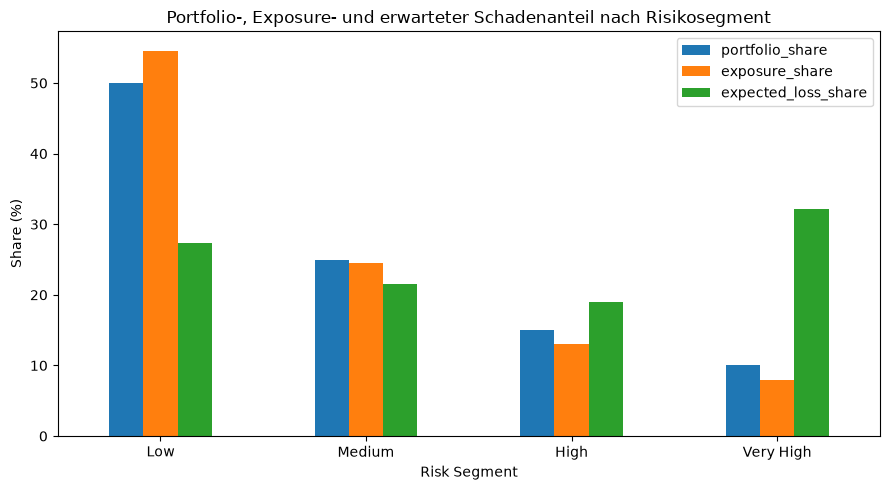

In [8]:
segment_plot_df = (
    segment_summary[
        [
            "risk_segment",
            "portfolio_share",
            "exposure_share",
            "expected_loss_share",
        ]
    ]
    .set_index("risk_segment")
    * 100
)

segment_plot_df.plot(
    kind="bar",
    figsize=(9, 5),
)

plt.ylabel("Share (%)")
plt.xlabel("Risk Segment")
plt.title(
    "Portfolio-, Exposure- und erwarteter Schadenanteil nach Risikosegment"
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Profil der Risikosegmente

Im nächsten Schritt werden die Risikosegmente anhand zentraler Fahrer- und Fahrzeugmerkmale beschrieben.

Damit soll untersucht werden, welche strukturellen Unterschiede zwischen `Low`, `Medium`, `High` und `Very High` bestehen und welche Merkmale die hohen Risikosegmente besonders charakterisieren.

In [9]:
numeric_segment_profile = (
    segmentation_df
    .groupby(
        "risk_segment",
        observed=True,
    )
    .agg(
        policies=("IDpol", "size"),
        mean_driver_age=("DrivAge", "mean"),
        median_driver_age=("DrivAge", "median"),
        mean_vehicle_age=("VehAge", "mean"),
        median_vehicle_age=("VehAge", "median"),
        mean_bonus_malus=("BonusMalus", "mean"),
        median_bonus_malus=("BonusMalus", "median"),
        mean_log_density=("log_density", "mean"),
        mean_tweedie_pp=("tweedie_pp", "mean"),
        mean_two_stage_pp=("two_stage_pp", "mean"),
    )
    .reset_index()
)

display(numeric_segment_profile)

,risk_segment,policies,mean_driver_age,median_driver_age,mean_vehicle_age,median_vehicle_age,mean_bonus_malus,median_bonus_malus,mean_log_density,mean_tweedie_pp,mean_two_stage_pp
0,Low,339008,47.296294,46.0,7.757923,7.0,51.851520,50.0,5.474284,84.092572,161.321769
1,Medium,169508,46.776878,46.0,5.947566,5.0,57.678723,50.0,6.350273,147.253503,220.704236
2,High,101695,42.221053,40.0,6.487182,6.0,70.415674,68.0,6.638187,243.003578,313.541696
3,Very High,67802,38.235583,37.0,7.053347,7.0,88.538214,90.0,6.719327,711.282388,646.914328


### Numerisches Segmentprofil

Die numerischen Segmentprofile zeigen klare strukturelle Unterschiede zwischen den Risikogruppen.

Besonders deutlich ist der Anstieg von `BonusMalus`: Der Mittelwert erhöht sich von rund 51,9 im `Low`-Segment auf rund 88,5 im `Very High`-Segment. Gleichzeitig sinkt das durchschnittliche Fahreralter von rund 47,3 auf 38,2 Jahre. Hohe Risikosegmente sind damit im Durchschnitt durch jüngere Fahrer und deutlich höhere Bonus-Malus-Werte gekennzeichnet.

Auch `log_density` steigt über die Risikosegmente hinweg kontinuierlich an. Dies weist darauf hin, dass dichter besiedelte Gebiete im Modell häufiger in höheren Risikosegmenten vertreten sind.

Für `VehAge` zeigt sich dagegen kein monotoner Verlauf. Das durchschnittliche Fahrzeugalter ist im `Medium`-Segment am niedrigsten und steigt in den höheren Segmenten wieder an. Dieses Muster steht im Einklang mit dem zuvor beobachteten nichtlinearen Zusammenhang zwischen Fahrzeugalter und Pure Premium.

Zusätzlich steigt auch die durchschnittliche Two-Stage-Pure-Premium über alle Segmente hinweg deutlich an und bestätigt damit die Tweedie-basierte Risikostaffelung aus einer zweiten Modellperspektive.

In [10]:
def categorical_overrepresentation(
    df,
    feature,
    segment_col="risk_segment",
    target_segment="Very High",
):
    overall_share = (
        df[feature]
        .value_counts(normalize=True)
        .rename("overall_share")
    )

    target_share = (
        df.loc[
            df[segment_col] == target_segment,
            feature,
        ]
        .value_counts(normalize=True)
        .rename("very_high_share")
    )

    result = (
        pd.concat(
            [overall_share, target_share],
            axis=1,
        )
        .fillna(0)
        .reset_index()
        .rename(columns={"index": feature})
    )

    result["representation_index"] = (
        result["very_high_share"]
        / result["overall_share"]
    )

    return result.sort_values(
        "representation_index",
        ascending=False,
    ).reset_index(drop=True)

In [11]:
vehgas_profile = categorical_overrepresentation(
    segmentation_df,
    "VehGas",
)

vehpower_profile = categorical_overrepresentation(
    segmentation_df,
    "VehPower",
)

vehbrand_profile = categorical_overrepresentation(
    segmentation_df,
    "VehBrand",
)

region_profile = categorical_overrepresentation(
    segmentation_df,
    "Region",
)


print("VehGas")
display(vehgas_profile)

print("\nVehPower")
display(vehpower_profile.head(10))

print("\nVehBrand – Top 10")
display(vehbrand_profile.head(10))

print("\nRegion – Top 10")
display(region_profile.head(10))

VehGas


,VehGas,overall_share,very_high_share,representation_index
0,Diesel,0.489867,0.528495,1.078854
1,Regular,0.510133,0.471505,0.924279



VehPower


,VehPower,overall_share,very_high_share,representation_index
0,13,0.004762,0.008112,1.703296
1,14,0.003466,0.005265,1.519133
2,11,0.027067,0.033539,1.239089
3,10,0.046244,0.056341,1.218333
4,6,0.219724,0.257824,1.173398
5,9,0.044372,0.050072,1.128458
6,12,0.012115,0.013451,1.110288
7,7,0.214452,0.208843,0.973848
8,4,0.170128,0.163712,0.962287
9,5,0.184098,0.152783,0.829900



VehBrand – Top 10


,VehBrand,overall_share,very_high_share,representation_index
0,B11,0.020036,0.047816,2.386431
1,B4,0.037136,0.065559,1.765342
2,B10,0.026116,0.037447,1.433881
3,B3,0.078752,0.094805,1.203846
4,B13,0.017961,0.019483,1.084732
5,B5,0.051257,0.050633,0.987818
6,B2,0.235779,0.223622,0.948439
7,B1,0.240019,0.225288,0.938627
8,B12,0.244868,0.202324,0.826258
9,B6,0.042105,0.030958,0.735245



Region – Top 10


,Region,overall_share,very_high_share,representation_index
0,R21,0.004463,0.041857,9.378621
1,R94,0.006661,0.012212,1.833462
2,R93,0.116982,0.183859,1.571692
3,R22,0.011790,0.018171,1.541140
4,R82,0.125001,0.164715,1.317713
5,R11,0.102935,0.110955,1.077922
6,R25,0.016066,0.017005,1.058467
7,R43,0.001956,0.002021,1.033172
8,R31,0.040243,0.038819,0.964623
9,R91,0.052809,0.049423,0.935893


### Kategorisches Profil des Very-High-Segments

Das `Very High`-Segment weist auch bei mehreren kategorialen Merkmalen erkennbare Überrepräsentationen auf.

Bei `VehGas` ist Diesel mit einem Repräsentationsindex von rund 1,08 nur leicht häufiger vertreten als im Gesamtportfolio. Der Unterschied ist damit vergleichsweise gering.

Bei `VehPower` zeigen insbesondere die Kategorien 13 und 14 erhöhte Repräsentationsindizes von rund 1,70 beziehungsweise 1,52. Da diese Kategorien im Gesamtportfolio jedoch nur geringe Anteile besitzen, sollte ihre Bedeutung nicht allein anhand des Repräsentationsindex bewertet werden. Auch die deutlich häufiger vorkommende Kategorie 6 ist mit einem Index von rund 1,17 im `Very High`-Segment überrepräsentiert.

Bei `VehBrand` fallen insbesondere `B11`, `B4` und `B10` auf. `B11` tritt im `Very High`-Segment relativ zum Gesamtportfolio rund 2,39-mal so häufig auf.

Die stärkste relative Überrepräsentation zeigt sich bei `Region`. `R21` besitzt einen Repräsentationsindex von rund 9,38, hat im Gesamtportfolio jedoch nur einen kleinen Anteil. Auch `R93`, `R82`, `R94` und `R22` sind im höchsten Risikosegment überrepräsentiert.

Die Repräsentationsindizes beschreiben Unterschiede in der Zusammensetzung der Segmente und dürfen nicht als kausale Risikoeffekte interpretiert werden. Besonders bei seltenen Kategorien muss zusätzlich deren absolute Portfoliohäufigkeit berücksichtigt werden.

In [12]:
segmentation_output = segmentation_df[
    [
        "IDpol",
        "Exposure",
        "two_stage_pp",
        "tweedie_pp",
        "risk_segment",
        "expected_loss_tweedie",
    ]
].copy()

SEGMENTATION_OUTPUT_PATH = (
    PROJECT_ROOT
    / "data"
    / "output"
    / "risk_segments.pq"
)

segmentation_output.to_parquet(
    SEGMENTATION_OUTPUT_PATH,
    index=False,
)

print("Shape:", segmentation_output.shape)
print(
    "Duplicate IDpol:",
    segmentation_output["IDpol"].duplicated().sum(),
)
print(
    "Missing risk segment:",
    segmentation_output["risk_segment"].isna().sum(),
)
print(
    "File exists:",
    SEGMENTATION_OUTPUT_PATH.exists(),
)
print(
    "Saved to:",
    SEGMENTATION_OUTPUT_PATH.relative_to(PROJECT_ROOT),
)

Shape: (678013, 6)
Duplicate IDpol: 0
Missing risk segment: 0
File exists: True
Saved to: data\output\risk_segments.pq


## Fazit – Risk Segmentation

Die finale Portfoliosegmentierung basiert auf der Tweedie-Pure-Premium als kanonischem Risikoscore.

Die Policen werden in vier operative Risikogruppen eingeteilt: `Low`, `Medium`, `High` und `Very High`. Besonders relevant ist das `Very High`-Segment, das nur rund 10 % aller Policen und etwa 7,9 % des gesamten Exposures umfasst, gleichzeitig jedoch rund 32,1 % der prognostizierten erwarteten Schadenkosten trägt.

Die Segmentprofile zeigen klare strukturelle Unterschiede. Höhere Risikosegmente sind insbesondere durch deutlich höhere `BonusMalus`-Werte, jüngere Fahrer und höhere Werte von `log_density` gekennzeichnet. Zusätzlich zeigen einzelne Fahrzeug-, Marken- und Regionskategorien eine erhöhte Repräsentation im höchsten Risikosegment.

Die Two-Stage-Pure-Premium steigt ebenfalls kontinuierlich über die Tweedie-basierten Risikosegmente hinweg an. Damit wird die grundlegende Risikostaffelung aus einer zweiten Modellperspektive bestätigt.

Die Segmentierung dient als operative Übersetzung der Modellprognosen und schafft eine Grundlage für gezielte Portfolioanalysen, Underwriting-Priorisierung, risikoorientierte Maßnahmen und spätere Power-BI-Auswertungen.

Die Segmentzugehörigkeit für alle 678.013 Policen wurde als reproduzierbares Datenartefakt unter `data/output/risk_segments.pq` gespeichert.